Dataset loaded from the task website.

Original dataset: (10, 2)

Sentiment distribution:
 sentiment
positive    5
negative    4
neutral     1
Name: count, dtype: int64


Multinomial Naive Bayes
              precision    recall  f1-score   support

    Negative       0.00      0.00      0.00         1
    Positive       0.50      1.00      0.67         1

    accuracy                           0.50         2
   macro avg       0.25      0.50      0.33         2
weighted avg       0.25      0.50      0.33         2


Logistic Regression
              precision    recall  f1-score   support

    Negative       0.00      0.00      0.00         1
    Positive       0.50      1.00      0.67         1

    accuracy                           0.50         2
   macro avg       0.25      0.50      0.33         2
weighted avg       0.25      0.50      0.33         2


MODEL PERFORMANCE COMPARISON


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Multinomial Naive Bayes,0.5,0.5,1.0,0.6667,0.0
1,Logistic Regression,0.5,0.5,1.0,0.6667,0.0


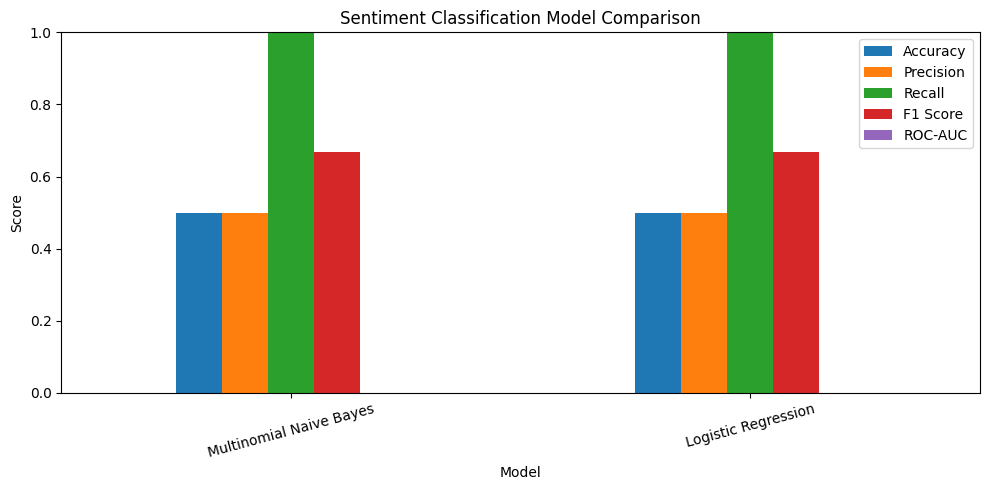

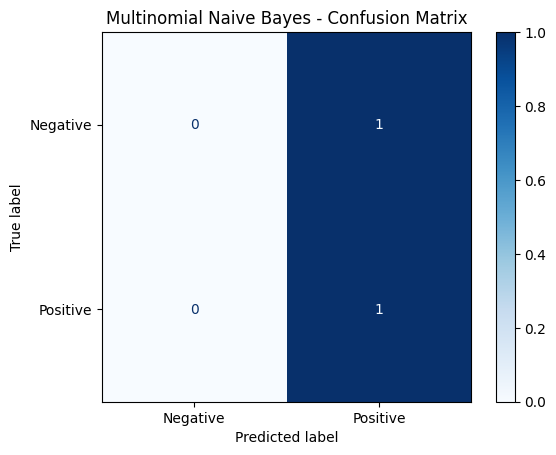

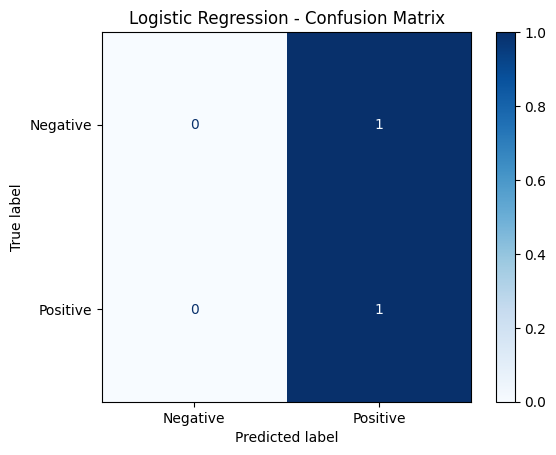


Review: This product is excellent and works perfectly.
Cleaned review: product excellent work perfectly
Multinomial Naive Bayes: Positive (predicted-class probability: 65.0%)
Logistic Regression: Positive (predicted-class probability: 61.0%)

Review: Terrible quality. I regret buying this product.
Cleaned review: terrible quality regret buying product
Multinomial Naive Bayes: Positive (predicted-class probability: 60.5%)
Logistic Regression: Positive (predicted-class probability: 58.8%)

Review: I do not recommend this item.
Cleaned review: not recommend item
Multinomial Naive Bayes: Negative (predicted-class probability: 52.5%)
Logistic Regression: Positive (predicted-class probability: 52.9%)


In [ ]:

# TASK 4: CUSTOMER REVIEW SENTIMENT CLASSIFICATION
# Models: Multinomial Naive Bayes + Logistic Regression

import pandas as pd
import numpy as np
import re
import html
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, ConfusionMatrixDisplay, roc_auc_score
)

# 1. LOAD DATASET
url = "https://www.datheon.in/datasets/sentiment_reviews.csv"

try:
    df = pd.read_csv(url)
    print("Dataset loaded from the task website.")
except Exception:
    print("Website download failed. Please upload sentiment_reviews.csv.")
    from google.colab import files
    uploaded = files.upload()
    filename = next(iter(uploaded))
    df = pd.read_csv(filename)

# 2. PREPARE DATA
df.columns = df.columns.str.strip().str.lower()

required = {"review_text", "sentiment"}
if not required.issubset(df.columns):
    raise ValueError(
        f"Expected columns {required}. Found: {df.columns.tolist()}"
    )

df = df[["review_text", "sentiment"]].dropna().copy()
df["review_text"] = df["review_text"].astype(str)
df["sentiment"] = df["sentiment"].astype(str).str.lower().str.strip()

print("\nOriginal dataset:", df.shape)
print("\nSentiment distribution:\n", df["sentiment"].value_counts())

# Keep positive and negative reviews for binary classification.
# Neutral reviews are excluded rather than relabelled.
df = df[df["sentiment"].isin(["positive", "negative"])].copy()
df = df[df["review_text"].str.strip() != ""]

if df["sentiment"].nunique() != 2 or df["sentiment"].value_counts().min() < 2:
    raise ValueError(
        "Not enough positive and negative examples. "
        "Please use the complete dataset, not just the 10-row sample."
    )

if len(df) < 50:
    print("\nWARNING: This dataset is very small. "
          "Performance scores may not be reliable.")

df["label"] = df["sentiment"].map({"negative": 0, "positive": 1})

# 3. TEXT CLEANING
# Remove HTML, URLs, punctuation and common English stopwords.
# Preserve negation words such as 'not' and 'never'.
import nltk
nltk.download("stopwords", quiet=True)
nltk.download("wordnet", quiet=True)
nltk.download("omw-1.4", quiet=True)

from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

stop_words = set(stopwords.words("english")) - {"no", "nor", "not", "never"}
lemmatizer = WordNetLemmatizer()

def clean_text(text):
    text = html.unescape(str(text))
    text = re.sub(r"<[^>]+>", " ", text)
    text = re.sub(r"http\S+|www\.\S+", " ", text.lower())
    text = re.sub(r"[^a-z\s]", " ", text)
    words = text.split()
    words = [
        lemmatizer.lemmatize(w)
        for w in words
        if w not in stop_words and len(w) > 1
    ]
    return " ".join(words)

df["cleaned_review"] = df["review_text"].apply(clean_text)

# 4. SPLIT DATA AND CREATE TF-IDF FEATURES
X_train_text, X_test_text, y_train, y_test = train_test_split(
    df["cleaned_review"],
    df["label"],
    test_size=0.20,
    random_state=42,
    stratify=df["label"]
)

tfidf = TfidfVectorizer(max_features=5000, ngram_range=(1, 2))
X_train = tfidf.fit_transform(X_train_text)
X_test = tfidf.transform(X_test_text)

# 5. TRAIN TWO MODELS
models = {
    "Multinomial Naive Bayes": MultinomialNB(),
    "Logistic Regression": LogisticRegression(max_iter=1000)
}

results = []

for name, model in models.items():
    model.fit(X_train, y_train)
    predictions = model.predict(X_test)
    probabilities = model.predict_proba(X_test)[:, 1]

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions, zero_division=0),
        "Recall": recall_score(y_test, predictions, zero_division=0),
        "F1 Score": f1_score(y_test, predictions, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, probabilities)
    })

    print(f"\n{'=' * 45}\n{name}\n{'=' * 45}")
    print(classification_report(
        y_test, predictions,
        labels=[0, 1],
        target_names=["Negative", "Positive"],
        zero_division=0
    ))

# 6. COMPARE MODELS
results_df = pd.DataFrame(results).sort_values("F1 Score", ascending=False)
print("\nMODEL PERFORMANCE COMPARISON")
display(results_df.round(4))

results_df.to_csv("task4_model_comparison.csv", index=False)

results_df.set_index("Model").plot(
    kind="bar", figsize=(10, 5), ylim=(0, 1)
)
plt.title("Sentiment Classification Model Comparison")
plt.ylabel("Score")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

# Confusion matrices
for name, model in models.items():
    ConfusionMatrixDisplay.from_estimator(
        model, X_test, y_test,
        display_labels=["Negative", "Positive"],
        cmap="Blues"
    )
    plt.title(name + " - Confusion Matrix")
    plt.show()

# 7. CUSTOM REVIEW PREDICTION FUNCTION
def predict_sentiment(review):
    cleaned = clean_text(review)
    vector = tfidf.transform([cleaned])

    print("\nReview:", review)
    print("Cleaned review:", cleaned)

    for name, model in models.items():
        prediction = model.predict(vector)[0]
        probability = model.predict_proba(vector)[0][prediction]
        label = "Positive" if prediction == 1 else "Negative"

        print(f"{name}: {label} "
              f"(predicted-class probability: {probability:.1%})")

# Try sample reviews
predict_sentiment("This product is excellent and works perfectly.")
predict_sentiment("Terrible quality. I regret buying this product.")
predict_sentiment("I do not recommend this item.")

# Optional: test your own review
custom_review = input("\nEnter your own review to test: ")
if custom_review.strip():
    predict_sentiment(custom_review)

print("\nTask 4 completed. Download this notebook as an .ipynb file.")
